# [실습] 머신러닝이란 무엇인가 — 첫 모델 만들기

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

# Chapter 1 실습. 해지 고객을 미리 찾을 수 있을까?

**필수 머신러닝 · Chapter 1**

| Part | 주제 |
| --- | --- |
| Part 1 | 데이터와 친해지기 |
| Part 2 | 현행 방법 만들기: 사람이 쓰는 규칙 |
| Part 3 | 모델 만들기와 실험 기록 |
| Part 4 | 비교하고 결정하기 |

## 분석 의뢰서

> **의뢰 부서**: 통신사 고객관리(CS)팀
> **목적**: 해지할 가능성이 높은 고객에게 미리 연락해 혜택을 제안하고 싶다.
> **제약**: 상담 인력이 한정되어 있어 모든 고객에게 연락할 수는 없다.
> **질문**: 해지할 고객을 미리 알 수 있을까?

## 오늘 실습의 질문

> **머신러닝 모델은 CS팀이 지금 쓰는 방법보다 얼마나 더 나은가? 그 차이는 모델을 도입할 만한 크기인가?**

이 질문에 답하려면 "지금 쓰는 방법"이 필요합니다. 그래서 여러분이 CS팀 담당자가 되어 **사람이 쓰는 규칙**을 먼저 만들고, 그 규칙과 모델을 **같은 평가용 데이터**에서 겨루게 합니다. 마지막에는 CS팀에 보낼 권고 메모를 씁니다.

## 이 노트북을 쓰는 법

| 표시 | 뜻 |
| --- | --- |
| **[직접 작성]** | 빈 코드 셀을 직접 채웁니다. 강의 교안의 코드를 보지 않고 먼저 써 보세요 |
| **[판단]** | 코드가 아니라 생각을 적는 칸입니다. 셀을 더블클릭해 `나의 답:` 뒤에 적으세요 |
| **[제공]** | 미리 채워 둔 코드입니다. 읽고 실행하세요 |
| **힌트** | 막혔을 때만 펼치세요 |

이 실습의 목표는 정확도를 높이는 것이 아니라 **모델의 점수를 무엇과 비교해 읽을지 스스로 정하는 것**입니다. 판단 칸을 비워 두면 실습이 끝난 것이 아닙니다.

## 준비

`WA_Fn-UseC_-Telco-Customer-Churn.csv` 파일을 이 노트북과 같은 폴더에 두세요.

In [13]:
# [제공] 이 실습에서 쓰는 라이브러리
import platform
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

# 그래프의 한글 글꼴 (환경에 맞는 글꼴이 없으면 글자가 깨질 수 있습니다)
if platform.system() == "Windows":
    plt.rcParams["font.family"] = "NanumGothic"
elif platform.system() == "Darwin":
    plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("blastchar/telco-customer-churn")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'telco-customer-churn' dataset.
Path to dataset files: /kaggle/input/telco-customer-churn


In [2]:
import os

print(os.listdir(path))


['WA_Fn-UseC_-Telco-Customer-Churn.csv']


---
# Part 1. 데이터와 친해지기

강의에서는 피처 세 개만 썼습니다. 여기서는 데이터 전체를 직접 살펴보고, 강의에서 일부러 뺐던 **누적 요금(TotalCharges)** 문제를 직접 해결합니다.

## 1-1. 데이터 불러오기

**[직접 작성]** 데이터를 불러와 `df`에 저장하고, 행과 열의 수, 그리고 처음 5행을 확인하세요.

<details><summary>힌트</summary>

`pd.read_csv("파일 이름")`, `df.shape`, `df.head()`를 차례로 쓰면 됩니다.
</details>

In [5]:
# 여기에 코드를 작성하세요

df0 = pd.read_csv(os.path.join(path, "WA_Fn-UseC_-Telco-Customer-Churn.csv"))
df = df0.copy()
print(f"행과 열의 수: {df.shape}")
print(df.head())

행과 열의 수: (7043, 21)
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService     MultipleLines InternetService OnlineSecurity OnlineBackup DeviceProtection TechSupport StreamingTV StreamingMovies        Contract PaperlessBilling              PaymentMethod  MonthlyCharges TotalCharges Churn
0  7590-VHVEG  Female              0     Yes         No       1           No  No phone service             DSL             No          Yes               No          No          No              No  Month-to-month              Yes           Electronic check           29.85        29.85    No
1  5575-GNVDE    Male              0      No         No      34          Yes                No             DSL            Yes           No              Yes          No          No              No        One year               No               Mailed check           56.95       1889.5    No
2  3668-QPYBK    Male              0      No         No       2          Yes                No             

## 1-2. 해지 비율 확인하기

**[직접 작성]** 해지 여부(`Churn`)별 고객 수와 비율을 확인하세요. 강의 Part 2에서 본 숫자와 같은지 확인합니다.

<details><summary>힌트</summary>

`df["Churn"].value_counts()`는 개수를, `value_counts(normalize=True)`는 비율을 보여줍니다.
</details>

In [3]:
# 여기에 코드를 작성하세요
print(f"해지 여부별 고객 수:\n {df['Churn'].value_counts()}")
print()
print(f"해지 여부별 비율:\n {df['Churn'].value_counts(normalize=True)}")

해지 여부별 고객 수:
 Churn
No     5174
Yes    1869
Name: count, dtype: int64

해지 여부별 비율:
 Churn
No     0.73463
Yes    0.26537
Name: proportion, dtype: float64


강의 Part 2에서 본 숫자와 동일하다.

## 1-3. 열의 자료형 확인하기

**[직접 작성]** 각 열의 자료형을 확인하세요.

<details><summary>힌트</summary>

`df.info()` 또는 `df.dtypes`를 쓰세요.
</details>

In [6]:
# 여기에 코드를 작성하세요
df.dtypes

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object


[판단] 월 요금(MonthlyCharges)과 누적 요금(TotalCharges)은 둘 다 금액입니다. 그런데 두 열의 자료형이 같은가요? 다르다면 무엇이 다른가요?

나의 답: 월 요금(MonthlyCharges): float64
             누적 요금(TotalCharges): object


> **[판단]** 월 요금(`MonthlyCharges`)과 누적 요금(`TotalCharges`)은 둘 다 금액입니다. 그런데 두 열의 자료형이 같은가요? 다르다면 무엇이 다른가요?
>
> 나의 답:

## 1-4. 누적 요금이 숫자가 아닌 이유 찾기

누적 요금 열에는 숫자로 바꿀 수 없는 값이 섞여 있습니다. `pd.to_numeric(열, errors="coerce")`는 열을 숫자로 바꾸되, 바꿀 수 없는 값은 빈 값(`NaN`)으로 만들어 줍니다.

**[직접 작성]** 아래 순서로 코드를 작성하세요.

1. 누적 요금을 숫자로 바꾼 결과를 `tc`에 저장한다
2. `tc`에서 빈 값이 몇 개인지 센다
3. 빈 값인 고객들의 `tenure`, `MonthlyCharges`, `TotalCharges`, `Churn`을 출력한다

<details><summary>힌트</summary>

빈 값 개수는 `tc.isna().sum()`, 빈 값인 행만 고르려면 `df[tc.isna()]` 또는 `df.loc[tc.isna(), [열 이름들]]`을 쓰세요.
</details>

In [4]:
# 1. 누적 요금을 숫자로 변환
tc = pd.to_numeric(df['TotalCharges'], errors="coerce")
# 2. 변환할 수 없어 생긴 빈 값 개수 확인
print(f"빈 값 개수: {tc.isna().sum()}")
# 3. 빈 값인 고객들의 정보 확인
print(df.loc[tc.isna(), 
    ['tenure', 'MonthlyCharges','TotalCharges','Churn']
    ])

빈 값 개수: 11
      tenure  MonthlyCharges TotalCharges Churn
488        0           52.55                 No
753        0           20.25                 No
936        0           80.85                 No
1082       0           25.75                 No
1340       0           56.05                 No
3331       0           19.85                 No
3826       0           25.35                 No
4380       0           20.00                 No
5218       0           19.70                 No
6670       0           73.35                 No
6754       0           61.90                 No


[판단] 빈 값인 고객들에게는 어떤 공통점이 있나요? 이 고객들의 누적 요금이 비어 있는 이유를 추측해 보세요.

나의 답: 빈 값인 고객들의 공통점은 tenure이 0으로 신규고객이다. 가입한 지 얼마 되지 않아 아직 누적 요금이 발생하지 않았거나 데이터가 기록되지 않아 TotalCharges가 비어 있는 것으로 추측된다.

> **[판단]** 빈 값인 고객들에게는 어떤 공통점이 있나요? 이 고객들의 누적 요금이 비어 있는 이유를 추측해 보세요.
>
> 나의 답:

## 1-5. 빈 값 처리 방법 정하기

빈 값을 처리하는 방법은 여러 가지입니다.

| 방법 | 코드 예시 | 생각해 볼 점 |
| --- | --- | --- |
| 해당 고객 삭제 | `df = df[tc.notna()]` | 고객을 데이터에서 지워도 되는가? |
| 0으로 채우기 | `tc.fillna(0)` | 이 고객들의 실제 누적 요금은 0인가? |
| 월 요금으로 채우기 | `tc.fillna(df["MonthlyCharges"])` | 첫 달 요금이 이미 청구되었다고 볼 수 있는가? |

정답은 없습니다. 1-4에서 추측한 이유에 가장 잘 맞는 방법을 고르세요. (이 세 방법은 데이터 전체의 통계값을 쓰지 않으므로, 평가용 데이터를 나누기 전에 적용해도 괜찮습니다.)

**[직접 작성]** 고른 방법으로 `df["TotalCharges"]`를 숫자형 열로 바꾸고, 빈 값이 남지 않았는지 확인하세요.

In [7]:
# 여기에 코드를 작성하세요
# 누적 요금을 숫자형으로 변환하고 빈 값은 0으로 채우기
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
).fillna(0)

# 빈 값이 남아 있는지 확인
print("빈 값 개수:", df["TotalCharges"].isna().sum())

# 자료형 확인
print("자료형:", df["TotalCharges"].dtype)

빈 값 개수: 0
자료형: float64


1. 해당고객 삭제: 신규 고객 11명을 삭제하면 고객 데이터가 사라지고 CS팀이 분석해야할 신규 고객도 제외될 수 있다.
2. 0으로 채우기: tenure=0인 고객은 실제 누적 요금이 아직 0일 가능성이 높다. 
3. 월 요금으로 채우기: 첫 달 요금이 이미 청구되었다고 가정해서 MonthlyCharges로 채우면 실제 누적 요금보다 크게 기록될 수 있다.

> **[판단]** 어떤 방법을 골랐나요? 그 이유를 한 줄로 적으세요. 이 결정을 CS팀에 보고할 때 알려야 할 점이 있다면 함께 적으세요.
>
> 나의 답:

## 1-6. 평가용 데이터 먼저 떼어 두기

강의 Part 2에서 배운 원칙입니다. **평가용 데이터는 모델이 학습하는 동안 보면 안 됩니다.** 이 실습에서는 규칙을 만들 때도 같은 원칙을 지킵니다. 그래서 데이터를 탐색하기 **전에** 평가용 20%를 먼저 떼어 둡니다. 이후의 탐색과 규칙 만들기는 학습용 데이터(`train_df`)만 보고 하고, 평가용 데이터(`test_df`)는 마지막 채점에만 씁니다.

**[직접 작성]** `df`를 학습용 80%와 평가용 20%로 나눠 `train_df`, `test_df`에 저장하세요. `random_state=42`, `stratify`는 해지 여부(`Churn`)로 합니다.

<details><summary>힌트</summary>

강의 3-2의 ③과 같습니다. 다만 이번에는 `X`, `y`가 아니라 `df` 전체를 나눕니다.

`train_df, test_df = train_test_split(df, test_size=..., random_state=..., stratify=...)`
</details>

In [8]:
# 여기에 코드를 작성하세요
train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df["Churn"]
)

print("전체 데이터:", df.shape)
print("학습용 데이터:", train_df.shape)
print("평가용 데이터:", test_df.shape)
print()
print("학습용 해지 비율:")
print(train_df["Churn"].value_counts(normalize=True))

print("\n평가용 해지 비율:")
print(test_df["Churn"].value_counts(normalize=True))

전체 데이터: (7043, 21)
학습용 데이터: (5634, 21)
평가용 데이터: (1409, 21)

학습용 해지 비율:
Churn
No     0.734647
Yes    0.265353
Name: proportion, dtype: float64

평가용 해지 비율:
Churn
No     0.734564
Yes    0.265436
Name: proportion, dtype: float64


[판단] 데이터를 탐색하기 전에 평가용 데이터를 먼저 떼어 두는 이유는 무엇인가요? 만약 평가용 데이터까지 보면서 규칙을 고친다면 어떤 문제가 생길까요?

나의 답: 
평가용 데이터는 모델이 실제로 얼마나 잘 작동하는지 객관적으로 확인하기 위해 학습 및 규칙 설정 과정에서 미리 분리해 둔다. 만약 평가용 데이터까지 보면서 규칙을 수정한다면, 해당 데이터에 맞춰 규칙이 최적화되어 실제 새로운 고객에게 적용했을 때의 성능을 정확하게 평가하기 어려워진다. 따라서 평가용 데이터는 마지막 성능 비교 단계에서만 사용해야 한다.

> **[판단]** 데이터를 탐색하기 전에 평가용 데이터를 먼저 떼어 두는 이유는 무엇인가요? 만약 평가용 데이터까지 보면서 규칙을 고친다면 어떤 문제가 생길까요?
>
> 나의 답:

### 체크포인트

여기까지 막혀서 다음으로 넘어가지 못했다면 **아래 셀만 실행**하세요. 1-5에서 빈 값을 0으로 채우는 한 가지 선택을 적용한 것이며, 정답이라는 뜻은 아닙니다. 1-6까지 끝낸 사람은 실행하지 않아도 됩니다.

In [ ]:
# [제공] 체크포인트: 1-6까지 끝낸 사람은 실행하지 않아도 됩니다
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df["Churn"])
print(len(train_df), len(test_df))

### 실습 도구 (실행만 하세요)

아래 셀은 이후 Part에서 쓰는 도구를 만듭니다. 읽어 보고 실행하세요.

| 도구 | 하는 일 |
| --- | --- |
| `churn_rate_by(열 이름)` | 학습용 데이터에서 그 열의 값별 해지율을 계산한다 (숫자 열은 `bins`로 구간을 나눈다) |
| `evaluate(이름, 예측)` | 평가용 데이터에서 정확도와, 해지 고객을 몇 명 찾았는지 보여 준다 |
| `make_data(피처 목록)` | 피처 목록으로 학습용·평가용 `X`, `y`를 만든다 |
| `record(...)` | 실험 결과를 기록표에 한 줄 추가한다 |

In [9]:
# [제공] 실습 도구
y_test = test_df["Churn"]

def churn_rate_by(col, bins=None):
    """학습용 데이터에서 col의 값별 해지율을 계산합니다. 숫자 열은 bins로 구간을 나눕니다."""
    key = pd.cut(train_df[col], bins) if bins is not None else train_df[col]
    return train_df.groupby(key, observed=True)["Churn"].apply(lambda s: (s == "Yes").mean()).round(3)

def evaluate(name, pred):
    """평가용 데이터에서 예측(Yes/No)을 채점합니다. 정확도를 돌려줍니다."""
    pred = pd.Series(np.asarray(pred), index=test_df.index)
    acc = (pred == y_test).mean()
    flagged = (pred == "Yes").sum()
    found = ((pred == "Yes") & (y_test == "Yes")).sum()
    total = (y_test == "Yes").sum()
    print(f"[{name}] 정확도 {acc:.3f} | 해지로 예측 {flagged}명 중 실제 해지 {found}명 | 전체 해지 고객 {total}명 중 {found}명을 찾음")
    return acc

def make_data(features):
    """피처 목록을 받아 학습용·평가용 X, y를 만듭니다. 평가용 고객은 항상 같습니다."""
    X = pd.get_dummies(df[features])
    return X.loc[train_df.index], X.loc[test_df.index], train_df["Churn"], test_df["Churn"]

experiment_log = []
def record(name, features, depth, accuracy):
    """실험 결과를 기록표에 한 줄 추가합니다."""
    experiment_log.append({
        "실험": name,
        "피처": ", ".join(features) if features else "-",
        "깊이": depth,
        "평가용 정확도": round(float(accuracy), 3),
    })
    print(f"기록: [{name}] {accuracy:.3f}")

## 1-7. 해지와 관련 있어 보이는 정보 찾기

이제 학습용 데이터에서 "어떤 고객이 많이 해지하는가"를 찾아봅니다. 이 관찰이 Part 2에서 규칙의 재료가 됩니다.

전체 평균 해지율은 약 26.5%입니다. 이보다 **눈에 띄게 높은** 집단을 찾는 것이 목표입니다.

**[직접 작성]** `churn_rate_by`로 계약 유형(`Contract`)별 해지율을 확인하세요.

In [10]:
# 여기에 코드를 작성하세요
churn_rate_by("Contract")

Contract
Month-to-month    0.427
One year          0.111
Two year          0.029
Name: Churn, dtype: float64


**[직접 작성]** 다른 열도 같은 방법으로 살펴보세요. **세 개 이상**의 열을 골라 해지율을 확인합니다. 숫자 열(`tenure`)은 구간을 나눠야 합니다.

<details><summary>힌트</summary>

열 이름 목록은 `df.columns.tolist()`로 볼 수 있습니다. 한 줄에 하나씩 `print(churn_rate_by("열 이름"))`을 쓰세요.

가입 기간처럼 숫자 열은 구간 경계를 함께 줍니다.

`churn_rate_by("tenure", bins=[-1, 6, 12, 24, 48, 72])`
</details>

In [11]:
# 여기에 코드를 작성하세요
df.columns.tolist()

['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [12]:
print(churn_rate_by("tenure", bins=[-1, 6, 12, 24, 48, 72]))
print()
print(churn_rate_by("gender"))
print()
print(churn_rate_by("Contract"))

tenure
(-1, 6]     0.522
(6, 12]     0.372
(12, 24]    0.286
(24, 48]    0.202
(48, 72]    0.099
Name: Churn, dtype: float64

gender
Female    0.266
Male      0.264
Name: Churn, dtype: float64

Contract
Month-to-month    0.427
One year          0.111
Two year          0.029
Name: Churn, dtype: float64


**[제공]** 해지 여부에 따라 가입 기간(`tenure`) 분포가 어떻게 다른지 그려 봅니다.

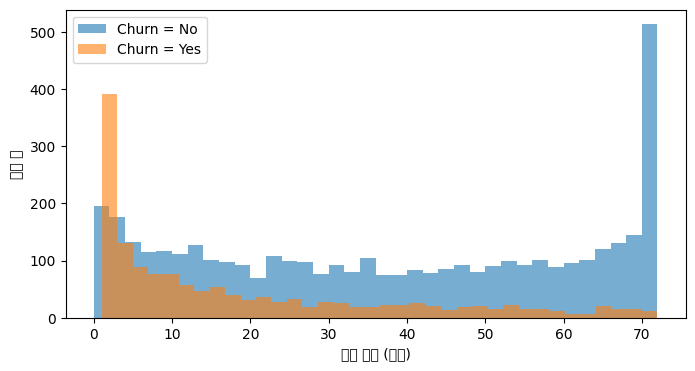

In [14]:
# [제공] 해지 여부별 가입 기간 분포 (학습용 데이터)
fig, ax = plt.subplots(figsize=(8, 4))
for label in ["No", "Yes"]:
    ax.hist(train_df.loc[train_df["Churn"] == label, "tenure"], bins=36, alpha=0.6, label=f"Churn = {label}")
ax.set_xlabel("가입 기간 (개월)")
ax.set_ylabel("고객 수")
ax.legend()
plt.show()

[판단] 해지율이 전체 평균보다 눈에 띄게 높은 집단을 두 개 이상 적어 보세요. (예: "○○인 고객은 해지율이 △△%")

나의 답:
전체 해지율: 26.5%
1. 가입 기간이 6개월 이하인 고객은 해지율이 **52.2%**로 전체 평균보다 높다.
2. 가입 기간이  6개월 초과 12개월 이하인 고객은 해지율이 **37.2%**로 전체 평균보다 높다.

따라서 가입 기간이 짧은 고객일수록 해지 위험이 높은 경향이 있다.

[판단] 이 집계만 보고 "그 조건을 바꾸게 하면 해지가 줄어든다"고 말할 수 있을까요? 강의 3-4의 세 번째 항목을 떠올려 보세요.

나의 답:
아니요. 이 집계만으로 조건을 바꾸면 해지가 줄어든다고 말할 수 없다. 특정 조건에서 해지율이 높다는 것은 두 변수 사이에 관련성이 있다는 뜻일 뿐, 그 조건이 해지의 직접적인 원인이라는 의미는 아니다. 예를 들어 월 단위 계약 고객의 해지율이 높더라도, 해지할 생각이 있는 고객이 처음부터 월 단위 계약을 선택했을 가능성도 있다. 따라서 조건을 바꾸면 해지가 줄어든다고 단정할 수 없다.

> **[판단]** 해지율이 전체 평균보다 눈에 띄게 높은 집단을 두 개 이상 적어 보세요. (예: "○○인 고객은 해지율이 △△%")
>
> 나의 답:

> **[판단]** 이 집계만 보고 "그 조건을 바꾸게 하면 해지가 줄어든다"고 말할 수 있을까요? 강의 3-4의 세 번째 항목을 떠올려 보세요.
>
> 나의 답:

---
# Part 2. 현행 방법 만들기: 사람이 쓰는 규칙

여러분이 CS팀 담당자라고 생각해 보세요. 머신러닝 없이, 오늘 전화할 고객을 고르는 **규칙 하나**를 만들어 봅시다. 강의 2-4에서 본 세 번째 베이스라인, "현행 규칙"입니다.

## 규칙을 만들 때의 약속

- 조건은 **두세 개를 넘기지 않습니다.** 현업에서 실제로 쓸 수 있을 만큼 단순해야 합니다.
- 근거는 **1-7에서 본 집계**입니다. 평가용 데이터를 보고 규칙을 고치지 않습니다.
- 규칙은 "이 조건에 맞는 고객은 해지 위험(Yes), 아니면 No"로 답합니다.

## 2-1. 베이스라인 계산

먼저 비교 기준을 만듭니다. 모든 고객에게 "No"라고 답하는 방법의 성적입니다.

**[직접 작성]** 평가용 고객 전원에게 "No"라고 답하는 예측을 만들어 `evaluate`로 채점하고, 정확도를 `baseline_acc`에 저장하세요.

<details><summary>힌트</summary>

`baseline_pred = pd.Series("No", index=test_df.index)`로 예측을 만들고, `baseline_acc = evaluate("전부 No", baseline_pred)`로 채점합니다.
</details>

In [15]:
# 여기에 코드를 작성하세요
# 평가용 고객 모두 해지하지 않는다고 예측
baseline_pred = pd.Series("No", index=test_df.index)

# 정확도 평가
baseline_acc = evaluate("전부 No", baseline_pred)

[전부 No] 정확도 0.735 | 해지로 예측 0명 중 실제 해지 0명 | 전체 해지 고객 374명 중 0명을 찾음


[판단] 나의 규칙(말로): 만약 월 단위 계약이면 해지 위험으로 본다.

이 조건을 고른 근거(1-7의 어떤 집계인가):

나의 답:

## 2-2. 나의 규칙 만들기

먼저 말로 적고, 그다음 코드로 옮깁니다.

> **[판단]** 나의 규칙(말로): 만약 ______ 이면 해지 위험으로 본다.
>
> 이 조건을 고른 근거(1-7의 어떤 집계인가):
>
> 나의 답:

**[직접 작성]** 규칙을 코드로 옮겨 평가용 고객에게 적용하고, 예측을 `rule_pred`에 저장하세요. 그다음 `evaluate`로 채점해 정확도를 `rule_acc`에 저장합니다.

<details><summary>힌트</summary>

조건은 `&`(그리고), `|`(또는)로 묶고, 조건마다 괄호를 칩니다. 예를 들어 "인터넷이 광케이블이고 월 요금이 80 이상"이라면

```python
condition = (test_df["InternetService"] == "Fiber optic") & (test_df["MonthlyCharges"] >= 80)
rule_pred = pd.Series(np.where(condition, "Yes", "No"), index=test_df.index)
rule_acc = evaluate("내 규칙", rule_pred)
```

이 예시는 형식만 보여주는 것입니다. 여러분의 규칙을 쓰세요.
</details>

In [ ]:
# 여기에 코드를 작성하세요
# 예측은 rule_pred, 정확도는 rule_acc라는 이름으로 저장하세요 (Part 3, 4에서 다시 씁니다)

> **[판단]** 내 규칙은 "전부 No"보다 정확도가 높은가요? 두 방법이 찾아낸 해지 고객 수도 비교해 보세요.
>
> 나의 답:

> **[판단]** 정확도는 비슷한데 찾아낸 해지 고객 수가 크게 다른 두 방법이 있다면, CS팀에는 어느 쪽이 더 쓸모 있을까요? 이유를 적어 보세요.
>
> 나의 답:

---
# Part 3. 모델 만들기와 실험 기록

이제 모델을 만들어 내 규칙과 겨룹니다. 강의 Part 3의 코드를 보지 말고 먼저 직접 써 보세요. 막히면 강의 3-2를 참고해도 됩니다.

## 3-1. 첫 모델 만들기

**[직접 작성]** 아래 순서로 작성하세요.

1. `make_data(["tenure", "MonthlyCharges", "Contract"])`로 `X_train, X_test, y_train, y_test`를 만든다
2. 깊이 2 결정트리(`max_depth=2`, `random_state=42`)를 학습한다
3. 평가용 데이터의 예측을 `evaluate`로 채점해 정확도를 `tree_acc`에 저장한다

<details><summary>힌트</summary>

강의 3-2의 ⑤와 같은 순서입니다. 채점은 `tree_acc = evaluate("트리(깊이 2)", model.predict(X_test))`로 합니다.
</details>

In [ ]:
# 여기에 코드를 작성하세요

## 3-2. 실험 기록표 시작하기

피처와 깊이를 바꿔 가며 여러 번 실험하면, 어떤 조건에서 몇 점이 나왔는지 금방 헷갈립니다. 그래서 실험마다 한 줄씩 기록을 남깁니다. 이 습관은 이후 Chapter에서도 계속 씁니다.

**[직접 작성]** 지금까지의 결과 세 가지(전부 No, 내 규칙, 깊이 2 트리)를 `record`로 기록하세요. 베이스라인과 규칙은 피처에 `[]`, 깊이에 `"-"`를 넣으면 됩니다.

<details><summary>힌트</summary>

`record("실험 이름", 피처 목록, 깊이, 정확도)` 형태입니다.
</details>

In [ ]:
# 여기에 코드를 작성하세요

## 3-3. 피처와 깊이를 바꿔 보기

**[직접 작성]** 피처를 추가하거나 깊이를 바꿔 가며 **세 번 이상** 실험하세요. 매번 `evaluate`로 채점하고 `record`로 기록합니다.

실험하기 전에, 피처를 고를 때 하나 확인할 것이 있습니다.

> **[판단]** 누적 요금(`TotalCharges`)을 피처로 쓰기 전에 생각해 보세요. 이 값은 "언제 찍힌 사진"일까요? 해지한 고객의 누적 요금은 해지 시점에서 멈춰 있지 않을까요? 이 피처를 쓸지 말지, 이유와 함께 적으세요. (정답은 Chapter 4에서 다시 확인합니다.)
>
> 나의 답:

<details><summary>힌트</summary>

한 번의 실험은 다음 네 줄입니다.

```python
features = ["tenure", "MonthlyCharges", "Contract", "InternetService"]
X_tr, X_te, y_tr, y_te = make_data(features)
m = DecisionTreeClassifier(max_depth=3, random_state=42).fit(X_tr, y_tr)
acc = evaluate("인터넷 추가, 깊이 3", m.predict(X_te))
record("인터넷 추가, 깊이 3", features, 3, acc)
```

깊이는 2~5 사이에서 바꿔 보세요. 더 깊게 하면 어떻게 되는지는 강의 3-5의 표에서 이미 봤습니다.
</details>

In [ ]:
# 실험 1


# 실험 2


# 실험 3

**[제공]** 실험 기록표를 정확도 순으로 봅니다.

In [ ]:
# [제공] 실험 기록표 보기
pd.DataFrame(experiment_log).sort_values("평가용 정확도", ascending=False, kind="stable")

> **[판단]** 가장 좋은 모델은 "전부 No"보다 몇 %p 나은가요? 내 규칙보다는 몇 %p 나은가요?
>
> 나의 답:

> **[판단]** 가장 좋은 모델이 해지 고객을 몇 명 찾아냈나요? 내 규칙이 찾아낸 수와 비교해 보세요.
>
> 나의 답:

## 3-4. 가장 나은 모델의 규칙 읽기

**[직접 작성]** 기록표에서 가장 나은 실험을 골라 그 모델을 다시 학습하고, `plot_tree`로 그리세요.

<details><summary>힌트</summary>

강의 3-3의 ⑦을 참고하세요. 깊이 3 트리는 글자가 작아지므로 `plt.figure(figsize=(20, 8))`처럼 그림을 크게 하세요.
</details>

In [ ]:
# 여기에 코드를 작성하세요

> **[판단]** "Yes"로 예측하는 잎을 하나 골라, 그 잎에 도착하는 고객의 조건을 말로 풀어 쓰세요. 그 잎의 고객 중 실제 해지 비율은 얼마인가요? (`value`로 계산)
>
> 나의 답:

---
# Part 4. 비교하고 결정하기

이제 질문으로 돌아옵니다. **모델은 CS팀이 지금 쓰는 방법(내 규칙)보다 얼마나 나은가? 그 차이는 도입할 만한 크기인가?**

## 4-1. 예상 걸기

곧 다른 수강생들의 규칙과 모델 점수를 한 표에서 함께 봅니다. 표를 열기 **전에** 먼저 예상을 적어 두세요. 틀려도 괜찮습니다. 예상이 빗나간 지점이 오늘 가장 많이 배우는 곳입니다.

> **[판단]** 예상 ① 교실 전체에서 "모델이 규칙을 이긴 사람"은 몇 %일까요? (대략의 비율로)
>
> 나의 답:

> **[판단]** 예상 ② 교실에서 가장 높은 규칙 정확도는 어느 정도일까요? 그 규칙은 조건이 많을까요, 적을까요?
>
> 나의 답:

## 4-2. 공유용 한 줄 만들기

**[직접 작성]** `my_rule_text`에 나의 규칙을 한 줄로 적으세요. (예: `"월 단위 계약이면서 가입 12개월 이하"`)

In [ ]:
my_rule_text = ""

**[제공]** 공유 표에 붙여 넣을 한 줄과, 내 실험 기록표를 출력합니다.

In [ ]:
# [제공] 공유용 한 줄 + 실험 기록표
log = pd.DataFrame(experiment_log)
models = log[~log["실험"].isin(["전부 No", "내 규칙"])]
best_row = models.sort_values("평가용 정확도", ascending=False, kind="stable").iloc[0]

print("공유 표에 붙여 넣으세요:")
print(f"규칙: {my_rule_text} | 규칙 정확도 {rule_acc:.3f} | 최고 모델 {best_row['실험']} {best_row['평가용 정확도']:.3f}")
print()
log.sort_values("평가용 정확도", ascending=False, kind="stable")

## 4-3. 공유 표를 본 뒤

> **[판단]** 예상 ①, ②는 맞았나요? 가장 크게 빗나간 것은 무엇이고, 왜 빗나갔다고 생각하나요?
>
> 나의 답:

> **[판단]** 조건이 적고 단순한 규칙과 조건이 많은 규칙 중, 모델과 더 비슷한 점수를 낸 것은 어느 쪽이었나요?
>
> 나의 답:

> **[판단]** 모델이 규칙을 몇 %p 이긴다면 CS팀은 모델을 도입해야 할까요? 규칙은 누구나 이해하고 내일부터 쓸 수 있지만 모델은 그렇지 않다는 점도 함께 생각해 보세요.
>
> 나의 답:

## 4-4. CS팀 권고 메모

분석 결과를 CS팀 팀장에게 메시지로 보낸다고 생각하고 쓰세요. 팀장은 머신러닝 용어를 모릅니다. 아래 네 가지가 모두 들어가야 합니다.

1. **무엇을 예측했는가** (누가, 어떤 정보로, 무엇을)
2. **지금 쓰는 방법(내 규칙)과 비교해 얼마나 나은가** (정확도와, 찾아낸 해지 고객 수 모두)
3. **권고**: 모델 도입 / 규칙 유지 / 보류 중 하나를 고르고, 이유를 쓴다
4. **주의할 점**: 1-5의 빈 값 처리 결정, 타깃 정의의 한계(강의 2-1), 아직 확인하지 못한 것

> **[판단]** CS팀 권고 메모:
>
> 1. 예측한 것:
>
> 2. 현행 방법과의 비교:
>
> 3. 권고와 이유:
>
> 4. 주의할 점:
>
> 나의 답:

---
# 마무리

## 이 Chapter의 판단 포인트

> **정확도 74%는 좋은 숫자인가? 베이스라인을 보기 전까지는 알 수 없다.**

## 개인 검증 체크리스트에 추가

오늘 실습에서 내가 실제로 겪은 일을 바탕으로, 체크리스트의 첫 줄을 내 말로 적으세요.

예: "모델 점수를 보면 '전부 No'와 현행 규칙의 점수를 먼저 찾는다."

> **[판단]** 나의 체크리스트 1번:
>
> 나의 답:

## 제출물

- 이 노트북 (모든 **[판단]** 칸을 채운 상태)
- 4-2에서 만든 공유용 한 줄

수고했습니다. 다음 Chapter 2에서는 숫자를 예측하는 **회귀**를 배웁니다.